In [11]:
import math
import torch
from torch import nn
from torch.nn import functional as F
torch.set_num_threads(2)

In [12]:
import sys
import torch
import torchvision

print(sys.executable)
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
x = torch.tensor([1., 2., 3.], device=device)
print(x, x.device, (x * x).sum().item())

/usr/bin/python3
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
CUDA available: True
tensor([1., 2., 3.], device='cuda:0') cuda:0 14.0


# Images, labels and batches

An MNIST example is a 28 x 28 greyscale image and a label from 0 to 9. The following code downloads the
images and returns them with a channel dimension, with pixel values scaled to [−1, 1]. A batch of 64 therefore
has shape (64, 1, 28, 28); its labels have shape (64,). The loader uses 50,000 examples for training and reserves
10,000 different examples for validation.

In [13]:
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import MNIST
import matplotlib.pyplot as plt

In [14]:
def load_data():
    dataset = MNIST("data", train=True, download=True)
    order = torch.randperm(60000, generator=torch.Generator().manual_seed(3801))
    images = dataset.data[order].unsqueeze(1).float()/127.5 - 1
    labels = dataset.targets[order]
    return images[:50000], labels[:50000], images[50000:], labels[50000:]

torch.Size([50000, 1, 28, 28]) torch.Size([50000])


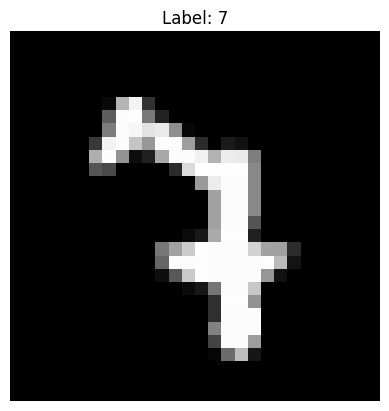

In [15]:
images, labels, validation_images, validation_labels = load_data()
print(images.shape, labels.shape)
plt.imshow(images[0, 0], cmap="gray", vmin=-1, vmax=1)
plt.title(f"Label: {labels[0].item()}")
plt.axis("off")
plt.show()

# Exercise
Display a different example. Find its brightest and darkest pixels with min() and max(). What does
images[:64].shape return? Which axis selects the image, and which axes select a pixel?

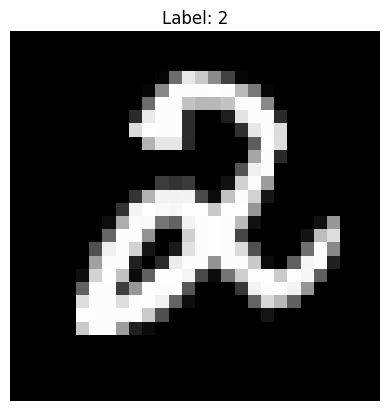

Brightest pixel value: 1.0
Darkest pixel value: -1.0
torch.Size([64, 1, 28, 28])


In [16]:
imgNum = 10
img = images[imgNum, 0]
imgLabel = labels[imgNum].item()
plt.imshow(img, cmap="gray", vmin=-1, vmax=1)
plt.title(f"Label: {imgLabel}")
plt.axis("off")
plt.show()
print(f"Brightest pixel value: {img.max()}")
print(f"Darkest pixel value: {img.min()}")
print(images[:64].shape)
# First axis selects the image
# Second axis selects the colour channel
# Last two axes select a pixel by its row and column

# Turning pixels into scores for each class
Flattening an image gives a vector $x \in R^{784}$. Our network has 16 hidden units:
$$
h = ReLU(W1x + b1), \quad z = W2h + b2, \quad ReLU(a) = max(0, a).
$$
The ten entries of z, called logits, give a score for each digit, and the network predicts the digit with the largest
score. Because the first layer maps 784 pixel values to 16 hidden units and the second maps those units to ten
scores, W1 has shape 16 x 784 and W2 has shape 10 x 16, with corresponding bias vectors of length 16 and 10.


In [17]:
def make_model(width=16):
    return nn.Sequential(nn.Flatten(), nn.Linear(784, width),
                         nn.ReLU(), nn.Linear(width, 10))

In [41]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = make_model().to(device)
x, y = images[:64].to(device), labels[:64].to(device)
logits = model(x)
print(logits.shape)
print(logits.argmax(dim=1)[:10], y[:10])
print(sum(p.numel() for p in model.parameters()))

torch.Size([64, 10])
tensor([3, 3, 3, 3, 3, 3, 3, 3, 3, 3], device='cuda:0') tensor([7, 0, 2, 1, 2, 7, 0, 6, 4, 7], device='cuda:0')
12730


# Exercise
Explain why the output has shape (64, 10). Count the weights and biases by hand. Before training, should these
predictions agree with the labels?

The output has shape (64,10) because there are 64 samples, and for each of the samples, it outputs the logit for each digit for that sample.

*Including both biases, the network contains
$$
784 \times 16 + 16 + 16 \times 10 + 10 = 12,730
$$
parameters. Before training, its random weights bear no useful relationship to the digit labels, so we expect
poor predictions. Uniform random guesses would be correct 10% of the time, although an individual untrained
network may favour some classes and achieve a different accuracy*

# Losses and gradient updates
Softmax converts the ten logits into probabilities:
$$
p_k =
\frac{e^{z_k}}{\Sigma^9_{j=0}e^{z_j}},
\quad
\ell (z,y) = - \log p_y
$$
If the correct digit receives probability 0.1, the loss is about 2.303; if it receives probability 0.9, the loss is
about 0.105. Training tries to reduce this loss over many examples. F.cross_entropy combines softmax and the
logarithm numerically stably and averages over the batch. Give it the logits directly.

In [19]:
loss = F.cross_entropy(logits, y)
probabilities = logits.softmax(dim=1)
print(loss.item(), probabilities[0], probabilities[0].sum().item())

2.3225271701812744 tensor([0.0868, 0.0811, 0.0776, 0.0750, 0.0700, 0.0850, 0.1226, 0.1389, 0.1211,
        0.1418], device='cuda:0', grad_fn=<SelectBackward0>) 1.0


# Exercise
For the first image, inspect the probability assigned to its true label and compare `-probabilities[0, y[0]].log()`
with the batch loss. Why are they generally different?
The gradient tells us how the loss changes when each parameter changes. Plain gradient descent uses $\theta \leftarrow \theta - \eta \nabla_{\theta} L$.
Here we use Adam, which adjusts the update using running estimates of the gradients. We will study optimisers
in more detail later.

In [28]:
trueLabel = y[0]
print(f"Image one true label: {trueLabel}")
print(f"Probability assigned to true label: {probabilities[0,trueLabel]}")
print(f"Loss: {-probabilities[0, y[0]].log()}")
print(f"Batch Loss: {loss.item()}")

Image one true label: 7
Probability assigned to true label: 0.13892163336277008
Loss: 1.9738452434539795
Batch Loss: 2.3225271701812744


The loss is lower for the first image than the batch loss. They are generally different as the model performance will vary for each specific sample, and the batch loss is only an average.

In [29]:
def train(model, images, labels, device, steps=150, learning_rate=0.003):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    model.train()
    for step in range(steps):
        index = torch.randint(len(images), (64,))
        x, y = images[index].to(device), labels[index].to(device)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        if (step + 1) % 25 == 0:
            print(step + 1, round(loss.item(), 3))
    return history

25 0.653
50 0.514
75 0.551
100 0.335
125 0.326
150 0.29


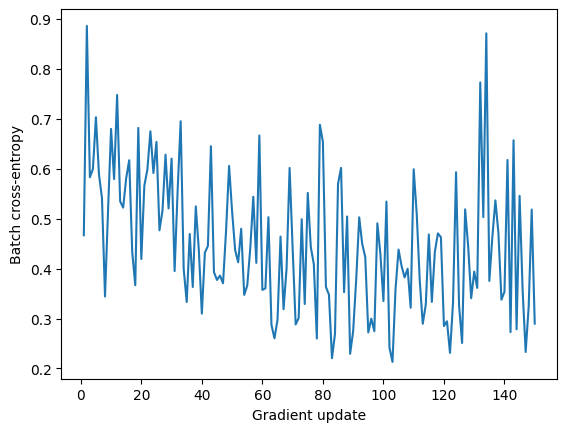

In [30]:
history = train(model, images, labels, device)
plt.plot(range(1, len(history)+1), history)
plt.xlabel("Gradient update")
plt.ylabel("Batch cross-entropy")
plt.show()

# Exercise
Match each line of the loop to one operation: choose a batch, predict, measure error, clear old gradients,
differentiate, update parameters. Why do the losses sometimes rise between updates?

```python
def train(model, images, labels, device, steps=150, learning_rate=0.003):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    model.train()
    for step in range(steps):
        index = torch.randint(len(images), (64,)) # choose a batch
        x, y = images[index].to(device), labels[index].to(device)
        logits = model(x) # predict
        loss = F.cross_entropy(logits, y) # measure error
        optimizer.zero_grad() # clear old gradients
        loss.backward() # differentiate
        optimizer.step() # update parameters
        history.append(loss.item())
        if (step + 1) % 25 == 0:
            print(step + 1, round(loss.item(), 3))
    return history
```

Losses sometimes rise between updates as the same is selected randomly each time, so the model may perform worse on some random batches, but the overall trend is a reduction in loss.

# Check the predictions and improve them
Validation examples are used to measure performance and are never passed to the optimiser. We can then
measure accuracy, the fraction whose predicted label is correct:
$$
\text{accuracy} = \frac{1}{N} \sum_{i=1}^{N}
\mathbf{1}\left\{\arg\max_k f_\theta(x_i)_k = y_i\right\}
$$

In [31]:
@torch.no_grad()
def accuracy(model, images, labels, device):
    model.eval()
    correct = 0
    for x, y in zip(images.split(256), labels.split(256)):
        correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(images)

In [32]:
score = accuracy(model, validation_images, validation_labels, device)
print(f"Validation accuracy: {100*score:.2f}%")

Validation accuracy: 87.53%


After 150 updates with seed 3801, batches of 64 and a learning rate of 0.003, this network reached 84.52%
validation accuracy, producing the predictions and training loss shown below. Your results may differ slightly
because numerical calculations can vary between environments.

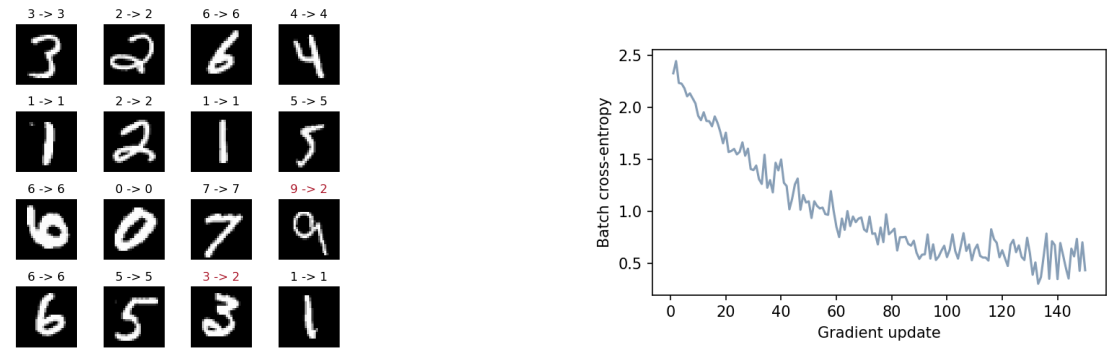

Figure 1: True label → prediction for the first 16 validation images, and the training loss. Incorrect predictions
are red

# Exercise
Make a new model with 32 hidden units and train it from fresh weights for the same number of updates. Compare
the parameter count, validation accuracy and loss. Next change only the learning rate to 0.001 or 0.01. Keep
the random seed, batch size and update count fixed when comparing two choices. Which change helped, and did
it help every digit equally?
For the wider network, change `make_model()` to `make_model(width=32)` and rerun the cells from model creation
through training and validation.


In [55]:
device = "cuda" if torch.cuda.is_available() else "cpu"

def load_data():
    dataset = MNIST("data", train=True, download=True)
    order = torch.randperm(60000, generator=torch.Generator().manual_seed(3801))
    images = dataset.data[order].unsqueeze(1).float()/127.5 - 1
    labels = dataset.targets[order]
    return images[:50000], labels[:50000], images[50000:], labels[50000:]

images, labels, validation_images, validation_labels = load_data()
x, y = images[:64].to(device), labels[:64].to(device)

def make_model(width=16):
    return nn.Sequential(nn.Flatten(), nn.Linear(784, width), nn.ReLU(), nn.Linear(width, 10))

def train(model, images, labels, device, steps=150, learning_rate=0.003):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    model.train()
    for step in range(steps):
        index = torch.randint(len(images), (64,))
        x, y = images[index].to(device), labels[index].to(device)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        #if (step + 1) % 25 == 0:
            #print(step + 1, round(loss.item(), 3))
    return history

def calculateLoss(model, x, y):
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  probabilities = logits.softmax(dim=1)
  return loss.item()

@torch.no_grad()
def accuracy(model, images, labels, device):
    model.eval()
    correct = 0
    for x, y in zip(images.split(256), labels.split(256)):
        correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(images)

torch.manual_seed(3801)
model1 = make_model(width=16).to(device)

torch.manual_seed(3801)
model2 = make_model(width=32).to(device)

torch.manual_seed(3801)
model3 = make_model(width=32).to(device)

torch.manual_seed(3801)
history1 = train(model1, images, labels, device)

torch.manual_seed(3801)
history2 = train(model2, images, labels, device)

torch.manual_seed(3801)
history3 = train(model3, images, labels, device, learning_rate=0.01)

print(f"\n16 hidden unit parameter count: {sum(p.numel() for p in model1.parameters())}")
print(f"32 hidden unit parameter count: {sum(p.numel() for p in model2.parameters())}")

print(f"\n16 hidden unit accuracy: {accuracy(model1, validation_images, validation_labels, device)}")
print(f"32 hidden unit accuracy: {accuracy(model2, validation_images, validation_labels, device)}")
print(f"32 hidden unit accuracy, 0.01 lr: {accuracy(model3, validation_images, validation_labels, device)}")

print(f"\n16 hidden unit loss: {calculateLoss(model1, x, y)}")
print(f"32 hidden unit loss: {calculateLoss(model2, x, y)}")
print(f"32 hidden unit loss, 0.01 lr: {calculateLoss(model3, x, y)}")

@torch.no_grad()
def per_digit_accuracy(model, images, labels, device):
    model.eval()
    digit_accuracy = {}

    for i in range(10):
        correct = 0
        total = 0

        for x, y in zip(images.split(256), labels.split(256)):
            predictions = model(x.to(device)).argmax(dim=1).cpu()

            # Select only images whose true label is digit i
            mask = (y == i)
            correct += (predictions[mask] == y[mask]).sum().item()
            total += mask.sum().item()

        digit_accuracy[i] = round(correct / total, 5) if total > 0 else 0

    return digit_accuracy

print(f"\nPer-digit accuracy:")
print(f"16 hidden unit: {per_digit_accuracy(model1, images, labels, device)}")
print(f"32 hidden unit: {per_digit_accuracy(model2, images, labels, device)}")
print(f"16 hidden unit, 0.01 lr: {per_digit_accuracy(model3, images, labels, device)}")


16 hidden unit parameter count: 12730
32 hidden unit parameter count: 25450

16 hidden unit accuracy: 0.7258
32 hidden unit accuracy: 0.8756
32 hidden unit accuracy, 0.01 lr: 0.8475

16 hidden unit loss: 0.8656792044639587
32 hidden unit loss: 0.34618937969207764
32 hidden unit loss, 0.01 lr: 0.3991079032421112

Per-digit accuracy:
16 hidden unit: {0: 0.88801, 1: 0.92782, 2: 0.63682, 3: 0.68005, 4: 0.60535, 5: 0.42755, 6: 0.845, 7: 0.87345, 8: 0.64365, 9: 0.77574}
32 hidden unit: {0: 0.91774, 1: 0.96577, 2: 0.82857, 3: 0.79526, 4: 0.86852, 5: 0.90571, 6: 0.94739, 7: 0.9113, 8: 0.78647, 9: 0.84707}
16 hidden unit, 0.01 lr: {0: 0.72531, 1: 0.94964, 2: 0.77183, 3: 0.86403, 4: 0.86214, 5: 0.91596, 6: 0.94334, 7: 0.89945, 8: 0.76951, 9: 0.7979}
